# 11e Classical forecasts and stock

11b used SARIMA, the best time-series model, and seasonal naive on all 726 products. Here the classical models from
07a go into exactly the same simulation, on the 150-product sample: SARIMA, additive Holt-Winters and ETS, next to
seasonal naive. On the sample the best model is the 07a SARIMA itself, so its row doubles as the check against 11b.
We use both the textbook safety stock and the calibrated one from 11c, a 95% target, a 7-day lead time and the base
costs (all assumptions). The question: does a better point forecast buy lower stock costs?

In [1]:
import sys, warnings
sys.path.append("../src")
from config import BEST_NAME
BEST_SHORT = BEST_NAME.split(" (")[0]      # the best time-series model from 07h, stored as 'best'
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import (ROOT, RAW, INTERIM, PROCESSED, TABLES, FIGS, ORIGINS, SEED, LEAD_TIME,
                    HOLDING_RATE, STOCKOUT_MULTIPLE, FIG_STYLE, NAMES, COLORS, make_dirs)
from break_detection import weekly_ca_prices
from pipeline import price_daily_frame, simulate_inventory, summarise_inventory, intermittency
from metrics import paired_test

make_dirs()
plt.rcParams.update(FIG_STYLE)
WRITTEN = []
SL = 0.95
MODELS = ["seasonal_naive", "ets", "hw_add", "sarima", "best"]

## Load

In [2]:
sample = pd.read_csv(TABLES / "classical_sample_items.csv")
fc = pd.read_parquet(TABLES / "comparison_forecasts.parquet")      # every model on the 150 products (10)
fc = fc[fc["model"].isin(MODELS)].assign(variant="static")
scales = pd.read_csv(PROCESSED / "backtest_errors.csv", parse_dates=["origin"])[["item_id", "origin", "mase_scale"]].drop_duplicates()
long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
long_df = long_df[long_df["item_id"].isin(sample["item_id"])]
calendar = pd.read_csv(RAW / "calendar.csv", parse_dates=["date"])
prices = pd.read_csv(RAW / "sell_prices.csv", dtype={"store_id": "category"})
price_wk = weekly_ca_prices(prices, calendar, sample["item_id"].tolist())
del prices
days = pd.date_range(ORIGINS[1] + pd.Timedelta(days=1), periods=28 * 6)
price_daily = price_daily_frame(price_wk, days)
inter = intermittency(long_df, ORIGINS[0])
print(fc["model"].value_counts().to_dict())

{'hw_add': 29400, 'sarima': 29400, 'best': 29400, 'ets': 29400, 'seasonal_naive': 29400}


## The rule

The same policy as 11b, with safety stock re-estimated at each origin from past errors only. The calibrated version
pools the scaled 7-day error sums within each category and model, over the 150 products.

## Simulate

In [3]:
POL = [(m, "static") for m in MODELS]
normal = simulate_inventory(fc, ORIGINS, price_daily, POL, [SL], LEAD_TIME, inter, HOLDING_RATE, STOCKOUT_MULTIPLE)

f = fc.merge(scales, on=["item_id", "origin"])          # fc already has the category column
f["e"] = f["actual"] - f["forecast"]
sums = []
for (item, origin, model, cat), g in f.groupby(["item_id", "origin", "model", "category"]):
    s = np.convolve(g.sort_values("date")["e"].to_numpy(), np.ones(LEAD_TIME), mode="valid") / g["mase_scale"].iloc[0]
    sums.append(pd.DataFrame({"origin": origin, "model": model, "category": cat, "r7": s}))
sums = pd.concat(sums, ignore_index=True)
scale_of = scales.set_index(["item_id", "origin"])["mase_scale"]
cat_of = sample.set_index("item_id")["category"]
cache = {}

def conformal_ss(item, model, variant, origin, lead_time, sl, past_errors):
    """Pooled, scaled lead-time error quantile from earlier origins (the 11c rule)."""
    key = (cat_of[item], model, origin, sl)
    if key not in cache:
        pool = sums[(sums["category"] == key[0]) & (sums["model"] == model) & (sums["origin"] < origin)]["r7"].to_numpy()
        n = len(pool)
        cache[key] = np.quantile(pool, min(1.0, np.ceil((n + 1) * sl) / n), method="higher")
    return max(0.0, scale_of[(item, origin)] * cache[key])

conf = simulate_inventory(fc, ORIGINS, price_daily, POL, [SL], LEAD_TIME, inter, HOLDING_RATE, STOCKOUT_MULTIPLE, ss_fn=conformal_ss)
items = pd.concat([normal.assign(method="normal formula"), conf.assign(method="conformal")], ignore_index=True)
items.to_csv(TABLES / "stock_items.csv", index=False)
WRITTEN.append(TABLES / "stock_items.csv")
print(len(items), "item simulations")

1500 item simulations


## Totals

In [4]:
summ = summarise_inventory(items, by=("method", "model", "service_level"))
summ.to_csv(TABLES / "stock_summary.csv", index=False)
WRITTEN.append(TABLES / "stock_summary.csv")
print(summ[["method", "model", "n_items", "fill_rate", "cycle_service_level", "avg_inventory_value", "holding_cost",
            "stockout_cost", "total_cost"]].round(4).to_string(index=False))

        method          model  n_items  fill_rate  cycle_service_level  avg_inventory_value  holding_cost  stockout_cost  total_cost
     conformal           best      150     0.9900               0.8992           37962.0476     4368.2356      3892.5845   8260.8201
     conformal            ets      150     0.9880               0.9007           38977.8676     4485.1245      4658.1472   9143.2717
     conformal         hw_add      150     0.9877               0.8905           39399.7515     4533.6700      4778.1422   9311.8122
     conformal         sarima      150     0.9915               0.9045           36983.0628     4255.5853      3600.9615   7856.5468
     conformal seasonal_naive      150     0.9887               0.8861           40272.0058     4634.0390      4339.5048   8973.5439
normal formula           best      150     0.9796               0.8447           33410.6984     3844.5187      7389.8569  11234.3756
normal formula            ets      150     0.9767               0.837

## Paired comparisons, product by product, and a bootstrap interval for the total difference

In [5]:
rng = np.random.default_rng(SEED)
rows = []
for method, g in items.groupby("method"):
    cost = g.pivot(index="item_id", columns="model", values="total_cost")
    fill = g.pivot(index="item_id", columns="model", values="fill_rate")
    for a in ["sarima", "hw_add"]:
        for b in ["ets", "best", "seasonal_naive"]:
            d = (cost[a] - cost[b]).to_numpy()
            boot = d[rng.integers(0, len(d), size=(5000, len(d)))].sum(axis=1)
            t = paired_test(cost[a] - cost[b], seed=SEED)
            rows.append({"method": method, "model_a": a, "model_b": b, "n_items": len(d),
                         "total_cost_diff": d.sum(), "total_diff_pct": d.sum() / cost[b].sum(),
                         "total_ci_low": np.quantile(boot, 0.025), "total_ci_high": np.quantile(boot, 0.975),
                         "median_item_cost_diff": t["median_diff"], "p_value_cost": t["p_value"],
                         "median_fill_rate_diff": float(np.median(fill[a] - fill[b])),
                         "p_value_fill": paired_test(fill[a] - fill[b], seed=SEED)["p_value"]})
tests = pd.DataFrame(rows)
tests.to_csv(TABLES / "stock_tests.csv", index=False)
WRITTEN.append(TABLES / "stock_tests.csv")
print(tests.round(4).to_string(index=False))

        method model_a        model_b  n_items  total_cost_diff  total_diff_pct  total_ci_low  total_ci_high  median_item_cost_diff  p_value_cost  median_fill_rate_diff  p_value_fill
     conformal  sarima            ets      150       -1286.7249         -0.1407    -2877.8226       -70.4598                -0.0731        0.4626                  0.000        0.7451
     conformal  sarima           best      150        -404.2733         -0.0489    -1322.9286       369.2036                 0.1470        0.7950                  0.000        0.6117
     conformal  sarima seasonal_naive      150       -1116.9970         -0.1245    -2498.7803       -87.0029                -0.6984        0.0468                  0.000        0.7173
     conformal  hw_add            ets      150         168.5405          0.0184     -237.2270       620.4682                 0.1738        0.1602                  0.000        0.3787
     conformal  hw_add           best      150        1050.9921          0.1272      

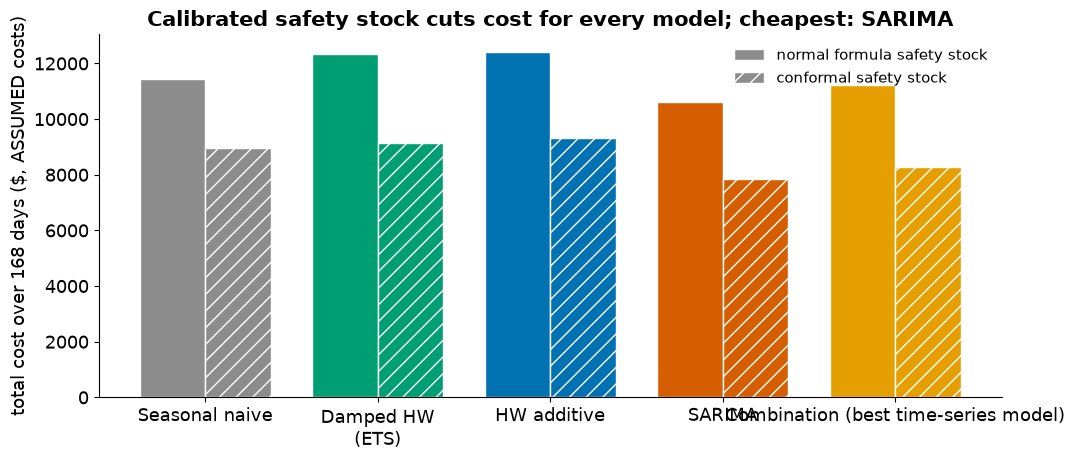

In [6]:
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(MODELS))
for k, (method, hatch) in enumerate([("normal formula", ""), ("conformal", "//")]):
    s = summ[summ["method"] == method].set_index("model").loc[MODELS]
    ax.bar(x + (k - 0.5) * 0.38, s["total_cost"], 0.38, color=[COLORS[m] for m in MODELS], hatch=hatch,
           edgecolor="white", label=f"{method} safety stock")
ax.set_xticks(x, [NAMES[m].replace("Holt-Winters ", "HW ").replace(" (ETS)", "\n(ETS)") for m in MODELS])
ax.set_ylabel("total cost over 168 days ($, ASSUMED costs)")
pv = summ.pivot(index="model", columns="method", values="total_cost")
cheapest = pv["conformal"].idxmin()
if (pv["conformal"] < pv["normal formula"]).all():
    ax.set_title(f"Calibrated safety stock cuts cost for every model; cheapest: {NAMES[cheapest]}")
else:
    ax.set_title(f"Cheapest with calibrated safety stock: {NAMES[cheapest]}")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGS / "classical_stock_cost.png")
WRITTEN.append(FIGS / "classical_stock_cost.png")
plt.show()

## Check: the best model and seasonal naive must match 11b for these products

In [7]:
ref = pd.read_csv(PROCESSED / "inventory_item_kpis.csv")      # the simulation saved by 11b
ref = ref[(ref["lead_time"] == LEAD_TIME) & (ref["service_level"] == SL) & ref["item_id"].isin(sample["item_id"])]
mine = normal[normal["model"].isin(["best", "seasonal_naive"])]
chk = mine.merge(ref, on=["item_id", "policy"], suffixes=("", "_11b"))
print(f"{len(chk)} item-policy rows; max |cost difference| {np.abs(chk['total_cost'] - chk['total_cost_11b']).max():.4f}, "
      f"max |fill-rate difference| {np.abs(chk['fill_rate'] - chk['fill_rate_11b']).max():.5f}")
assert len(chk) == 300 and np.allclose(chk["total_cost"], chk["total_cost_11b"], atol=0.01)
assert items.groupby(["method", "model"])["item_id"].nunique().eq(150).all()
print("all checks passed")

300 item-policy rows; max |cost difference| 0.0000, max |fill-rate difference| 0.00000
all checks passed


## What we found

With the calibrated safety stock, SARIMA has the lowest total cost on the 150 products ($7,857), then seasonal naive
($8,974), ETS ($9,143) and additive Holt-Winters ($9,312). SARIMA against ETS is 14.1% cheaper, with a bootstrap
interval from -$2,878 to -$70, and against seasonal naive 12.4% cheaper (-$2,499 to -$87). With the textbook safety
stock every model costs 27-35% more and misses the 95% target (83-87% of cycles), as in 11c; SARIMA is still the
cheapest ($10,631). Fill rates differ by less than a point between models. The best model is the 07a SARIMA on these
products, so its rows equal SARIMA's, and it matches 11b product by product.

One warning about the ranking: on these 150 products seasonal naive comes out cheaper than ETS with both safety
stocks, although ETS forecasts better. A few products dominate the totals of a small sample, so close models can
swap places. For stock planning the safe conclusions are that the safety-stock method matters more than the choice
between good models, and that SARIMA is a good choice on these products.

With LightGBM, in the earlier version of the project, SARIMA was also the cheapest here, and 2.9% cheaper than
LightGBM, with an interval that crossed zero.

## What comes next

`11f_texas_and_wisconsin` reruns the whole pipeline on two other states.

In [8]:
# files this notebook wrote
from pathlib import Path
ROOT = Path('..').resolve()
written = [ROOT / p for p in ['outputs/tables/stock_items.csv', 'outputs/tables/stock_summary.csv', 'outputs/tables/stock_tests.csv', 'outputs/figures/classical_stock_cost.png']]
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

outputs\tables\stock_items.csv 360 KB
outputs\tables\stock_summary.csv 2 KB
outputs\tables\stock_tests.csv 2 KB
outputs\figures\classical_stock_cost.png 81 KB
